# Parte Específica: Visualização explanatória 1

**Variáveis:** faixas de `Total_Trans_Ct` (quantidade de transações em 12 meses) e ritmo de uso no 4º trimestre
(`Total_Ct_Chng_Q4_Q1 < 0,60` = queda forte; `≥ 0,60` = uso estável ou crescente), com a taxa de cancelamento
(`Attrition_Flag`) em cada combinação.

**Tipo de gráfico:** barras agrupadas, escolhido pelo grupo (Pedro). Os parâmetros (faixas, limite de 0,60, cores e
rótulos) são os mesmos da versão interativa na página `3_relacoes.py` do dashboard.

In [1]:
# [IA] Claude Code – importacao das bibliotecas, leitura do dataset tratado e pasta de saida
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

CAMINHO_DADOS = Path("../../out/parte_especifica/bankchurners_tratado.csv")
PASTA_SAIDA = Path("../../out/parte_especifica")
PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(CAMINHO_DADOS)
df["cancelou"] = (df["Attrition_Flag"] == "Attrited Customer").astype(int)

In [2]:
# [IA] Claude Code – faixas de transacoes e ritmo no Q4 (mesmos cortes da pagina 3 do dashboard)
FAIXAS_TRANS = [0, 39, 59, 79, np.inf]
ROTULOS_TRANS = ["< 40 transações", "40 a 59 transações", "60 a 79 transações", "80+ transações"]
LIMITE_QUEDA_Q4 = 0.60

RITMO_QUEDA = "Queda forte no Q4 (Q4/Q1 < 0,60)"
RITMO_ESTAVEL = "Uso estável/crescente (Q4/Q1 ≥ 0,60)"
CORES_RITMO = {RITMO_QUEDA: "#C44E52", RITMO_ESTAVEL: "#4C72B0"}

df["faixa_trans"] = pd.cut(df["Total_Trans_Ct"], bins=FAIXAS_TRANS, labels=ROTULOS_TRANS, right=True)
df["ritmo_q4"] = np.where(df["Total_Ct_Chng_Q4_Q1"] < LIMITE_QUEDA_Q4, RITMO_QUEDA, RITMO_ESTAVEL)

taxa_geral = df["cancelou"].mean() * 100
print(f"Taxa geral de cancelamento: {taxa_geral:.1f}%")

Taxa geral de cancelamento: 16.1%


In [3]:
# [IA] Claude Code – taxa de cancelamento e quantidade de clientes em cada combinacao faixa x ritmo
resumo = (
    df.groupby(["faixa_trans", "ritmo_q4"], observed=True)["cancelou"]
    .agg(taxa=lambda s: s.mean() * 100, total="count")
    .reset_index()
)
resumo["taxa"] = resumo["taxa"].round(1)
resumo.pivot(index="faixa_trans", columns="ritmo_q4", values=["taxa", "total"])

taxa  \
ritmo_q4           Queda forte no Q4 (Q4/Q1 < 0,60)   
faixa_trans                                           
< 40 transações                                48.7   
40 a 59 transações                             56.9   
60 a 79 transações                              5.1   
80+ transações                                  0.4   

                                                         \
ritmo_q4           Uso estável/crescente (Q4/Q1 ≥ 0,60)   
faixa_trans                                               
< 40 transações                                    12.0   
40 a 59 transações                                 25.0   
60 a 79 transações                                  6.4   
80+ transações                                      1.4   

                                              total  \
ritmo_q4           Queda forte no Q4 (Q4/Q1 < 0,60)   
faixa_trans                                           
< 40 transações                               887.0   
40 a 59 transações                            946.0   
60 a 79 transações                            692.0   
80+ transações                                283.0   

                                                         
ritmo_q4           Uso estável/crescente (Q4/Q1 ≥ 0,60)  
faixa_trans                                              
< 40 transações                                   915.0  
40 a 59 transações                               1188.0  
60 a 79 transações                               2776.0  
80+ transações                                   2440.0

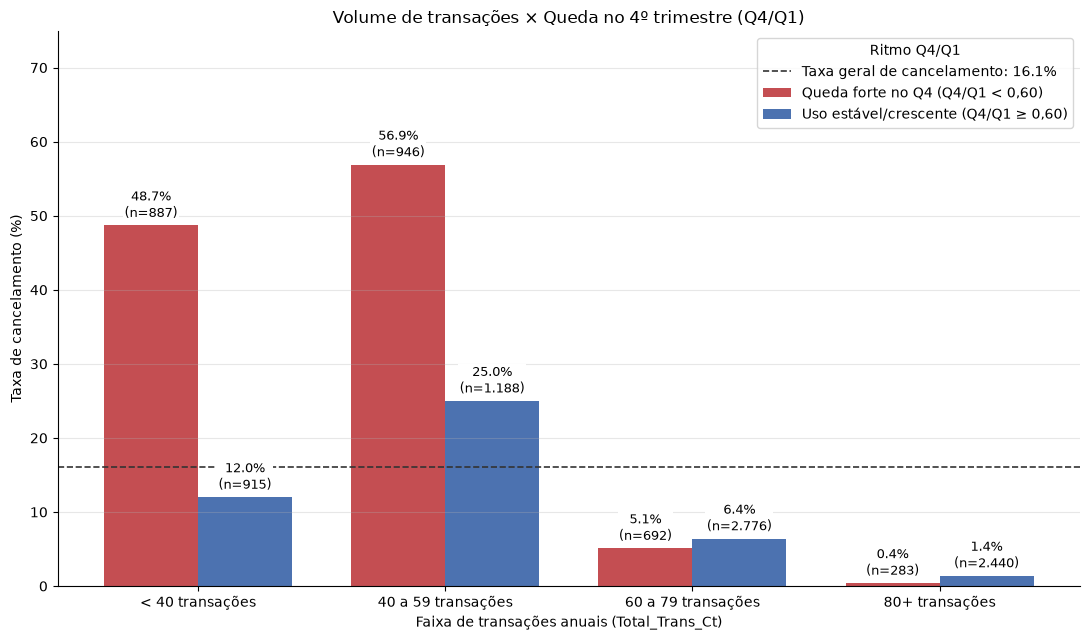

In [4]:
# [IA] Claude Code – grafico de barras agrupadas com linha da taxa geral e rotulos diretos (taxa e n)
fig, ax = plt.subplots(figsize=(11, 6.5))
largura = 0.38
posicoes = np.arange(len(ROTULOS_TRANS))

for deslocamento, ritmo in [(-largura / 2, RITMO_QUEDA), (largura / 2, RITMO_ESTAVEL)]:
    dados = resumo[resumo["ritmo_q4"] == ritmo].set_index("faixa_trans").reindex(ROTULOS_TRANS)
    barras = ax.bar(posicoes + deslocamento, dados["taxa"].fillna(0), width=largura,
                    color=CORES_RITMO[ritmo], label=ritmo)
    for barra, taxa, total in zip(barras, dados["taxa"], dados["total"]):
        if pd.notna(taxa):
            ax.annotate(f"{taxa:.1f}%\n(n={int(total):,})".replace(",", "."),
                        xy=(barra.get_x() + barra.get_width() / 2, barra.get_height()),
                        xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9,
                        bbox={"facecolor": "white", "edgecolor": "none", "pad": 1})

ax.axhline(taxa_geral, color="#333333", linestyle="--", linewidth=1.2,
           label=f"Taxa geral de cancelamento: {taxa_geral:.1f}%")

ax.set_title("Volume de transações × Queda no 4º trimestre (Q4/Q1)")
ax.set_xlabel("Faixa de transações anuais (Total_Trans_Ct)")
ax.set_ylabel("Taxa de cancelamento (%)")
ax.set_xticks(posicoes)
ax.set_xticklabels(ROTULOS_TRANS)
ax.set_ylim(0, min(resumo["taxa"].max() + 18, 108))
ax.legend(title="Ritmo Q4/Q1", loc="upper right")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
fig.savefig(PASTA_SAIDA / "viz_explanatoria_1_churn_transacoes_queda.png", dpi=150, bbox_inches="tight")
plt.show()

## Nota analítica

Texto do grupo (Pedro), do relatório `docs/rascunhos/relatorio_pedro_relacoes_visualizacoes.md`:

Na **Visualização Explanatória 1** (`src/parte_especifica/viz_explanatoria_1.ipynb`, figura `out/parte_especifica/viz_explanatoria_1_churn_transacoes_queda.png`), respondemos diretamente à pergunta de pesquisa cruzando os dois principais preditores comportamentais encontrados na EDA: faixas de volume anual de transações (`Total_Trans_Ct`: menos de 40, 40 a 59, 60 a 79 e 80 ou mais) e queda recente no ritmo de uso (`Total_Ct_Chng_Q4_Q1 < 0,60` contra `≥ 0,60`). O gráfico utiliza barras agrupadas com título de ação, linha tracejada na média geral de 16,1%, hierarquia cromática coerente (vermelho para alerta de queda no Q4 e azul para uso estável) e rótulos diretos com taxa e `n`. A leitura evidencia um efeito de patamar: clientes com 60 ou mais transações por ano cancelam bem abaixo da média, enquanto clientes abaixo desse limite — especialmente quando combinados à queda acentuada no 4º trimestre — concentram a zona crítica de cancelamento e oferecem o recorte mais objetivo para ações preventivas de retenção.